In [8]:
!pip install keras-tuner

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [keras-tuner]


ORIGINAL DATASET
Shape: (150, 4)

EIGENVALUES
[2.93808505 0.9201649  0.14774182 0.02085386]

EXPLAINED VARIANCE RATIO
[0.72962445 0.22850762 0.03668922 0.00517871]

CUMULATIVE EXPLAINED VARIANCE
[0.72962445 0.95813207 0.99482129 1.        ]

REDUCED DATASET
Original Shape: (150, 4)
Reduced Shape: (150, 2)


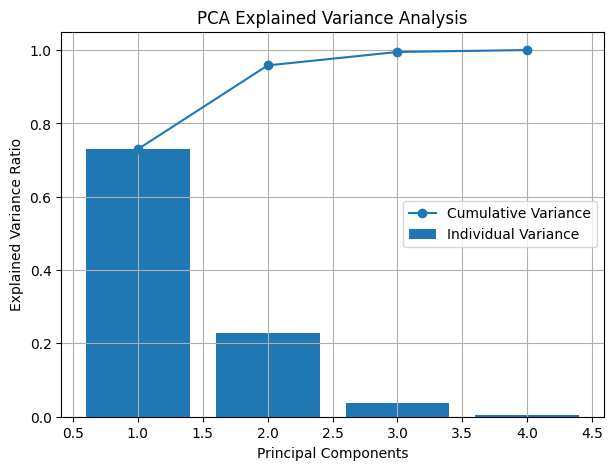

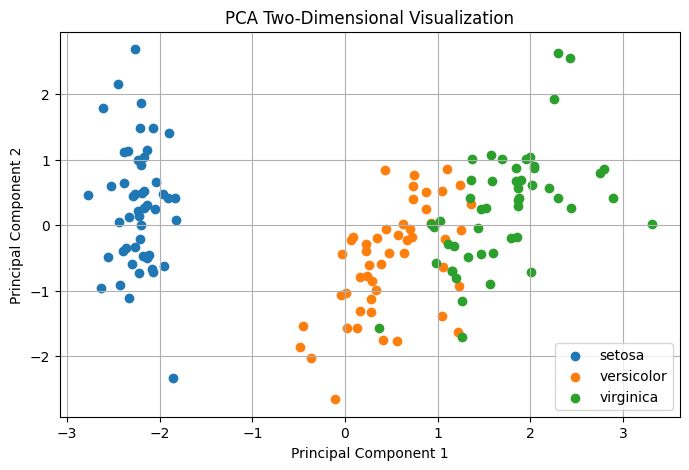


PRINCIPAL COMPONENTS
[[ 0.52106591 -0.26934744  0.5804131   0.56485654]
 [ 0.37741762  0.92329566  0.02449161  0.06694199]
 [ 0.71956635 -0.24438178 -0.14212637 -0.63427274]
 [-0.26128628  0.12350962  0.80144925 -0.52359713]]

Variance retained using 2 components: 0.9581320720000166


In [10]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# 1. Load dataset
iris = load_iris()

X = iris.data
y = iris.target

print("ORIGINAL DATASET")
print("Shape:", X.shape)

# 2. Standardize dataset
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

# 3. Apply PCA
pca = PCA()

X_pca = pca.fit_transform(X_scaled)

# 4. Display eigenvalues
print("\nEIGENVALUES")

print(pca.explained_variance_)

# 5. Explained variance ratio
print("\nEXPLAINED VARIANCE RATIO")

print(pca.explained_variance_ratio_)

# 6. Cumulative explained variance
cumulative_variance = np.cumsum(
    pca.explained_variance_ratio_
)

print("\nCUMULATIVE EXPLAINED VARIANCE")

print(cumulative_variance)

# 7. Select principal components
pca_2 = PCA(
    n_components=2
)

X_reduced = pca_2.fit_transform(
    X_scaled
)

print("\nREDUCED DATASET")

print("Original Shape:", X_scaled.shape)

print("Reduced Shape:", X_reduced.shape)

# 8. Plot explained variance
plt.figure(figsize=(7, 5))

plt.bar(
    range(1, 5),
    pca.explained_variance_ratio_,
    label="Individual Variance"
)

plt.plot(
    range(1, 5),
    cumulative_variance,
    marker="o",
    label="Cumulative Variance"
)

plt.xlabel("Principal Components")

plt.ylabel("Explained Variance Ratio")

plt.title("PCA Explained Variance Analysis")

plt.legend()

plt.grid()

plt.show()

# 9. Visualize reduced dataset
plt.figure(figsize=(8, 5))

for target in np.unique(y):

    plt.scatter(
        X_reduced[y == target, 0],
        X_reduced[y == target, 1],
        label=iris.target_names[target]
    )

plt.xlabel("Principal Component 1")

plt.ylabel("Principal Component 2")

plt.title("PCA Two-Dimensional Visualization")

plt.legend()

plt.grid()

plt.show()

# 10. Display PCA components
print("\nPRINCIPAL COMPONENTS")

print(pca.components_)

print(
    "\nVariance retained using 2 components:",
    sum(pca_2.explained_variance_ratio_)
)